# 04 — Manual backprop, by hand
Lecture 1, ~22-37% (search: "derivative of l with respect to l", then "one step of an optimization"). Phase 1, item 4 in [PLAN](../knowledge/PLAN.md). Previous: [03-visualise-graph](../knowledge/notes/03-visualise-graph.md).

**Where this fits.** In notebook 03 you worked out every slope in your head: `L` 1, `d` -2, `f` 4, `c` -2, `e` -2, `a` 6, `b` -4. Now you store them **on the boxes**, check every one by nudging, and then use them to make `L` move the way you want. That last step is one step of training.

**Done when** `draw_dot(L)` shows a correct `grad` in every box, each one confirmed by a nudge, and one step using those grads moved `L` in the direction you predicted.

Pure Python.

## 1. Add `grad` to Value
Copy your `Value` from notebook 03. Add one field: `grad`, starting at `0.0`.

`grad` means "if I nudge this box, how much does `L` move, per unit of nudge?" It's the slope from notebook 01, but stored on the box.

Question, answered before you code it: why start at **0** and not at 1 or `None`? What does a slope of 0 say about a box?

In [4]:
class Value:
    def __init__(self, data, label="", grad=0.0):
        self.data = data
        # this field will be used to track the previous Value in the computational graph
        self._prev = ()
        # this field will be used to track the operation that produced this Value
        self._op = ""
        self.label = label
        self.grad = grad

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        # create a new Value object to represent the result of the addition
        out = Value(self.data + other.data, label=f"({self.label}+{other.label})")
        # set the _prev field to track the previous Values in the computational graph
        out._prev = (self, other)
        # set the _op field to indicate that this Value was produced by addition
        out._op = "+"
        return out

    def __mul__(self, other):
        # create a new Value object to represent the result of the multiplication
        out = Value(self.data * other.data, label=f"({self.label}*{other.label})")
        # set the _prev field to track the previous Values in the computational graph
        out._prev = (self, other)
        # set the _op field to indicate that this Value was produced by multiplication
        out._op = "*"
        return out

# why start at 0 and not at 1 or None? What does a slope of 0 say about a box?
# starting .grad with 0, will set all node's .grad to zero which can allow us to
# calculate new slope... but wait! Backward-pass will already allows us to calculate\
# slope... I don't know. Teach me!
# None is the last thing one would want because it will cause error, 
# TypeError: unsupported operand type(s) for +: 'NoneType' and 'int'

## 2. Rebuild the graph
Same numbers as notebook 03, built fresh (notebook 03 left `a.data` at 100). Give `e`, `d` and `L` short labels by hand after creating them (`e.label = "e"`), so the picture stays readable.

In [5]:
a = Value(2.0, label="a")
b = Value(-3.0, label="b")
c = Value(10.0, label="c")
f = Value(-2.0, label="f")

e = a * b
e.label = "e"
d = e + c
d.label = "d"
L = d * f
L.label = "L"

## 3. Drawing helper (scaffolding)
Same as notebook 03. It already shows `grad` once a box has one.

In [6]:
# SCAFFOLDING (written by Claude): draws the receipt. You don't need to type this.
# Adapted from Karpathy's draw_dot in lectures/micrograd/micrograd_lecture_first_half_roughly.ipynb
from graphviz import Digraph


def trace(root):
    # walk _prev from the root (same idea as your traverse_graph), collect every node and edge once
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format="svg", graph_attr={"rankdir": "LR"})  # LR = left to right
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        label = getattr(n, "label", "")  # works before you've added .label
        text = f"{{ {label} | data {n.data:.4f} }}"
        if hasattr(n, "grad"):  # shows up once you add .grad in item 4
            text = f"{{ {label} | data {n.data:.4f} | grad {n.grad:.4f} }}"
        dot.node(name=uid, label=text, shape="record")  # a box per Value
        if n._op:
            dot.node(
                name=uid + n._op, label=n._op
            )  # a small op node (not a real Value)
            dot.edge(uid + n._op, uid)
    for child, parent in edges:
        dot.edge(str(id(child)), str(id(parent)) + parent._op)
    return dot

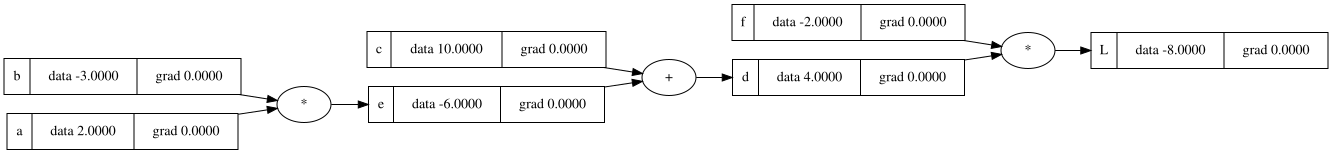

In [7]:
draw_dot(L)  # every grad should be 0.0

## 4. A nudge checker
Before you fill anything in, build the tool that will check you. Karpathy calls his `lol()`.

Shape: a function that, **inside itself**, builds the whole expression twice from plain numbers. The first time it's normal (`L1`). The second time it adds `h` to exactly one value (`L2`). It returns `(L2 - L1) / h`. That's the same rise over run as notebook 01.

Questions:
- Why build everything inside the function and not reuse the global `a`, `b`, `L`? (Hint: notebook 03, break 4.)
- `L2` and `L1` are `Value`s. What do you have to subtract?
- How do you nudge `e` or `d`, which are made by ops and not typed in?

In [ ]:
def backward_test():
    a = Value(2.0, label="a")
    b = Value(-3.0, label="b")
    c = Value(10.0, label="c")
    f = Value(-2.0, label="f")

    # Normal forward-pass
    e1 = a * b
    e1.label = "e1"
    d1 = e1 + c
    d1.label = "d1"
    L1 = d1 * f
    L1.label = "L1"

    h = 0.001
    # Normal forward-nudge-pass
    e2 = a * b
    e2.label = "e2"
    d2 = e2 + Value(10.0 + h, label="c2")
    d2.label = "d2"
    L2 = d2 * f
    L2.label = "L2"

    print(f"L1: {L1} | L2: {L2}")
    print(f"(L2 - L1) / h: {(L2.data - L1.data) / h}")

backward_test()


L1: Value(data=-8.0) | L2: Value(data=-8.001999999999999)
(L2 - L1) / h: -1.9999999999988916


## 5. Fill in the grads, right to left
One cell per step. In each one: set the grads **by hand**, redraw, and check every new number with your nudge checker.

1. `L`
2. `d` and `f`
3. `c` and `e`
4. `a` and `b`

You already know the numbers. To show you have the rule and not just the answers, write each grad as an expression of other boxes' `data` and `grad` (for example, `d.grad = ... * L.grad`), not as a typed number.

In [8]:
# 5.1  L

In [9]:
# 5.2  d and f

In [10]:
# 5.3  c and e

In [11]:
# 5.4  a and b

## 6. Use the grads: one step
Now make `L` go **up** (less negative). Nudge each **leaf** (`a`, `b`, `c`, `f`) by `0.01 * its grad`, then do the forward pass again and print `L.data`.

Predict first: does `L` go up or down? Roughly by how much?

Questions:
- Why only the leaves? What would happen if you changed `e.data` instead?
- Why do you have to rebuild `e`, `d` and `L`?

## 7. Break it
Predict each one, then run it. One break per cell.

1. Flip the sign: nudge each leaf by `-0.01 * grad`. What happens to `L`? Which sign will training use, given that `L` is a loss?
2. Set `L.grad = 2.0` instead of 1 and redo the expressions in section 5. What happens to every grad below it? Why?
3. Forget section 5.1 and leave `L.grad` at 0. What do your expressions give for every other box?
4. Run your nudge checker for `a` with `h = 1.0` instead of `0.001`. In notebook 01, a big `h` gave a wrong slope. Here it gives exactly 6. Why? (Hold `b`, `c` and `f` still: what kind of function of `a` is `L`?)
5. Step size 1.0 instead of 0.01 in section 6. Does `L` still move the way you predicted? By how much?

In [12]:
# break 1

In [13]:
# break 2

In [14]:
# break 3

In [15]:
# break 4

In [16]:
# break 5

## Notes / findings
Your own words, 3-4 sentences: what does a box's `grad` mean? Why is `L.grad` 1? Why did nudging the leaves by `0.01 * grad` make `L` go up?

_Your answer here:_